# Per-TF-site Kinase Correlation Panel (direct prediction + family expansion)

Different discovery algorithm from kinase_tf_group_panel_family.ipynb --
no Fisher's exact / module-or-family enrichment test involved at all.
For EACH TF phosphosite:

1. Take its own top-15 kinase_library-predicted kinases (motif-based,
   percentile_rank <= 15 -- same scoring as the family heatmap notebook).
2. Keep only the predicted kinases that have >=1 dynamic (differential)
   phosphosite of their own.
3. Test each of those kinases' dynamic site(s) for trajectory
   correlation against this TF site (pooled IL6+IL10, n=12, p<0.05 --
   same test as the group-panel notebooks, no r-magnitude threshold).
4. For every kinase that PASSES that direct test, look up its kinase
   FAMILY, find every OTHER kinase in that same family with a dynamic
   site, and test THEIR correlation against this TF site too.
5. Any family-mate that also passes gets added to this TF site's group.

Result: one group per TF site (kinases who passed directly + any
family-mates who passed via the expansion step), plotted and saved
INDIVIDUALLY -- one file per qualifying TF site.

## 0. Imports & paths

In [1]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import kinase_library as kl

CORR_METHOD   = "pearson"
CORR_P_THRESH = 0.05
KL_THRESH     = 15  # top-15 predicted kinases per TF site, by percentile_rank

psites_f       = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/TMT_control_centered_log2fc.csv"
desites_f      = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_ids_and_flanks.csv"
sig_sites_f    = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_res.csv"
phospho_data_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/stat_results_IL6IL10phosphopairwiseBMDMheatmap.csv"
tf1_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/DEG_motif_enrichment/common_degs_enr/sig_TF_results/out_files/sig_tomtom_TFs_withLabels.csv"
tf2_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/modisco/out_files/sig_modisco_TFs_withLabels.csv"
tf3_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/decoupler/out_files/sig_decoupler_TFs_withLabels.csv"

module_assignments_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3a/out_files/kinase_module_assignments.csv"
kinome_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/kinome_information.tsv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite"
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

## 1. Kinase family lookup

`module_df` gives kinase_library short names -- map to gene symbols
(needed to match against `geneSymbol` in the trajectory data), then
build the two lookups this notebook actually needs: gene -> family, and
family -> all genes in it.

In [2]:
module_df = pd.read_csv(module_assignments_f)

kinome = pd.read_csv(kinome_f, sep="\t")
kl_to_gene = dict(zip(kinome['KINASE'].str.upper(), kinome['GENE_NAME'].str.upper()))

module_df['kinase_gene'] = module_df['kinase'].str.upper().map(kl_to_gene)
n_unmapped = module_df['kinase_gene'].isna().sum()
if n_unmapped:
    unmapped_names = sorted(module_df.loc[module_df['kinase_gene'].isna(), 'kinase'].unique())
    print(f"WARNING: {n_unmapped} kinases had no gene-symbol mapping, falling back to kinase name as-is: {unmapped_names}")
    module_df.loc[module_df['kinase_gene'].isna(), 'kinase_gene'] = (
        module_df.loc[module_df['kinase_gene'].isna(), 'kinase'].str.upper()
    )

gene_to_family = dict(zip(module_df["kinase_gene"], module_df["family"]))
family_to_genes = module_df.groupby("family")["kinase_gene"].apply(set).to_dict()

print(f"Kinases with a family assignment: {len(gene_to_family)}  |  Families: {len(family_to_genes)}")

Kinases with a family assignment: 83  |  Families: 9


## 2. Dynamic TF phosphosites (need both flank sequences for scoring AND the id for trajectory lookup)

In [3]:
sig_sites = pd.read_csv(sig_sites_f)
sig_sites['geneSymbol'] = sig_sites['id'].str.split('_').str[0]
sig_sites['id']         = sig_sites['id'].str.split('_', n=1).str[1]
sig_sites_list          = sig_sites.id.tolist()

flank_source_df = pd.read_csv(phospho_data_f)
flank_source_df['geneSymbol'] = flank_source_df['id'].str.split('_').str[0]
flank_source_df['id']         = flank_source_df['id'].str.split('_', n=1).str[1]
flank_source_df = flank_source_df[["id", "geneSymbol", "VMsiteFlanks"]]

dyn_sites = flank_source_df.loc[flank_source_df.id.isin(sig_sites_list)].copy().reset_index(drop=True)

tf1_genes = pd.read_csv(tf1_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf2_genes = pd.read_csv(tf2_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf3_genes = pd.read_csv(tf3_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf_genes = list(set(tf1_genes + tf2_genes + tf3_genes))

dyn_tf_sites = dyn_sites.loc[dyn_sites.geneSymbol.isin(tf_genes)].copy().reset_index(drop=True)
dyn_tf_sites["site_label"] = dyn_tf_sites["geneSymbol"] + "_" + dyn_tf_sites["id"].str.split("_").str[1]
dup_mask = dyn_tf_sites["site_label"].duplicated(keep=False)
if dup_mask.any():
    suffix = dyn_tf_sites.groupby("site_label").cumcount().astype(str)
    dyn_tf_sites.loc[dup_mask, "site_label"] += "_dup" + suffix[dup_mask]

site_label_to_id = dict(zip(dyn_tf_sites["site_label"], dyn_tf_sites["id"]))

def get_site_type(seq):
    if 'y' in seq:
        return 'tyrosine'
    elif 's' in seq or 't' in seq:
        return 'ser_thr'
    return None

dyn_tf_sites["kin_type"] = dyn_tf_sites["VMsiteFlanks"].str.split("|").str[0].apply(get_site_type)
dyn_tf_sites_serthr = dyn_tf_sites.loc[dyn_tf_sites.kin_type == "ser_thr"].copy().reset_index(drop=True)

print(f"Dynamic Ser/Thr TF sites: {len(dyn_tf_sites_serthr)} "
      f"(dropped {len(dyn_tf_sites) - len(dyn_tf_sites_serthr)} tyrosine/unclassified)")

Dynamic Ser/Thr TF sites: 38 (dropped 4 tyrosine/unclassified)


## 3. Score each TF site against the Ser/Thr kinase panel -> top-15 predicted kinases per site

In [4]:
flank_df = (
    dyn_tf_sites_serthr[['id', 'site_label', 'VMsiteFlanks']]
    .assign(VMsiteFlanks=lambda df: df.VMsiteFlanks.str.split('|'))
    .explode('VMsiteFlanks')
    .rename(columns={'VMsiteFlanks': 'sequence'})
    .dropna(subset=['sequence'])
    .assign(sequence=lambda df: df.sequence.str.strip())
    .reset_index(drop=True)
)

pps_data = kl.PhosphoProteomics(flank_df, seq_col='sequence')
pps_data.percentile(kin_type='ser_thr', values_only=True)
percentile_ranks = pps_data.ser_thr_percentile_ranks.copy()
percentile_ranks['id'] = flank_df['id'].values
percentile_ranks['site_label'] = flank_df['site_label'].values

long = percentile_ranks.melt(id_vars=['id', 'site_label'], var_name='kinase', value_name='percentile_rank')
long['kinase'] = long['kinase'].str.upper()

site_kinase_rank = (
    long.groupby(['site_label', 'kinase'])['percentile_rank']
    .min()
    .reset_index()
)

top15_per_site = (
    site_kinase_rank[site_kinase_rank["percentile_rank"] <= KL_THRESH]
    .sort_values(["site_label", "percentile_rank"])
)
top15_per_site["kinase_gene"] = top15_per_site["kinase"].map(kl_to_gene)
top15_per_site.loc[top15_per_site["kinase_gene"].isna(), "kinase_gene"] = top15_per_site.loc[
    top15_per_site["kinase_gene"].isna(), "kinase"
]

print(f"Scored {site_kinase_rank.site_label.nunique()} sites x {site_kinase_rank.kinase.nunique()} kinases")
print(f"Top-15 kinase assignments: {top15_per_site.shape[0]} rows")

Scoring 42 ser_thr substrates
Calculating percentile for 42 ser_thr substrates


Percentile scoring: 100%|██████████| 311/311 [00:00<00:00, 43097.38it/s]

Scored 38 sites x 311 kinases
Top-15 kinase assignments: 621 rows


## 4. Trajectory data and dynamic-kinase-site lookup

Every kinase (any kinase with a family assignment) that has >=1 dynamic
phosphosite, at the individual-phosphosite level -- a gene can
contribute more than one row here if it has multiple dynamic sites.

In [5]:
traj_df = pd.read_csv(psites_f)
desites = pd.read_csv(desites_f)['id'].tolist()

all_kinase_genes = set(module_df["kinase_gene"])
kinase_dyn_sites = traj_df[
    traj_df["geneSymbol"].str.upper().isin(all_kinase_genes) & traj_df["id"].isin(desites)
].copy()

kinase_dyn_sites["site_label"] = (
    kinase_dyn_sites["geneSymbol"].str.upper() + "_" + kinase_dyn_sites["id"].str.split("_").str[1]
)
dup_mask = kinase_dyn_sites["site_label"].duplicated(keep=False)
if dup_mask.any():
    suffix = kinase_dyn_sites.groupby("site_label").cumcount().astype(str)
    kinase_dyn_sites.loc[dup_mask, "site_label"] += "_dup" + suffix[dup_mask]

kinase_row_by_label = {row["site_label"]: row for _, row in kinase_dyn_sites.iterrows()}

gene_to_dyn_site_labels = {}
for _, row in kinase_dyn_sites.iterrows():
    gene_to_dyn_site_labels.setdefault(row["geneSymbol"].upper(), []).append(row["site_label"])

print(f"Kinases with >=1 dynamic phosphosite: {len(gene_to_dyn_site_labels)}  |  "
      f"Total dynamic kinase phosphosites: {len(kinase_row_by_label)}")

Kinases with >=1 dynamic phosphosite: 12  |  Total dynamic kinase phosphosites: 16


## 5. Trajectory and correlation helpers

In [6]:
time_order = ["0m", "20m", "45m", "90m"]

unstim_cols = [c for c in traj_df.columns if "PBS_0" in c]
il6_cols    = [c for c in traj_df.columns if "IL6" in c]
il10_cols   = [c for c in traj_df.columns if "IL10" in c]

cytokine_cols_map = {"IL6": il6_cols, "IL10": il10_cols}
CYTOKINE_COLOR = {"IL6": "#d62728", "IL10": "#1f77b4"}
x = np.arange(len(time_order))

def single_site_trajectory(row, cytokine_cols):
    vals = []
    for t in time_order:
        time_cols = unstim_cols if t == "0m" else [c for c in cytokine_cols if t.rstrip("m") in c]
        vals.append(row[time_cols].mean())
    return np.array(vals)

def paired_correlation(row_a, row_b):
    """Pooled IL6+IL10 replicate samples, PBS excluded, n=12."""
    cols = il6_cols + il10_cols
    x_vals = row_a[cols].astype(float).values
    y_vals = row_b[cols].astype(float).values
    if CORR_METHOD == "spearman":
        r, p = stats.spearmanr(x_vals, y_vals)
    else:
        r, p = stats.pearsonr(x_vals, y_vals)
    return r, p

def get_markers(n):
    """Distinct marker shapes for up to ~11 entities before repeating."""
    shapes = ['o', '^', 'v', '<', '>', 'p', 'h', '8', '*', 'X', 'P']
    return [shapes[i % len(shapes)] for i in range(n)]

## 6. Per-TF-site discovery: direct prediction test, then family expansion

For each TF site:
1. Its own top-15 predicted kinases, restricted to ones with a dynamic
   phosphosite (`gene_to_dyn_site_labels`).
2. Test each candidate kinase SITE (a gene can have >1) for correlation
   against this TF site -- p<0.05 passes, no r threshold.
3. For every kinase GENE with >=1 passing site, pull its family, then
   test every OTHER family member's dynamic site(s) against this same
   TF site too (skip genes already tested in step 2, and skip families
   already expanded once for this TF site).
4. Final group for this TF site = every kinase site that passed, either
   directly or via family expansion. TF sites with zero passing kinases
   get no group and no plot.

In [7]:
correlation_results = []
discovered_groups = []  # [{"tf_site": site_label, "kinases": [...], "tf_best_r": {...}}]

for tf_label, tf_id in site_label_to_id.items():
    if tf_id not in traj_df["id"].values:
        continue
    tf_row = traj_df.loc[traj_df["id"] == tf_id].iloc[0]

    site_top15 = top15_per_site.loc[top15_per_site["site_label"] == tf_label,
                                     ["kinase", "kinase_gene", "percentile_rank"]]
    print(f"\n{tf_label}: top-15 predicted kinases")
    print(site_top15.to_string(index=False))

    predicted_genes = set(site_top15["kinase_gene"])
    candidate_genes = predicted_genes & set(gene_to_dyn_site_labels.keys())

    passing_sites = {}   # site_label -> r  (both direct hits and family-expansion hits)
    tested_genes = set()
    expanded_families = set()

    def test_gene_sites(gene):
        """Test every dynamic site belonging to this gene against tf_row; return True if >=1 passes."""
        any_passed = False
        for site_label in gene_to_dyn_site_labels.get(gene, []):
            kinase_row = kinase_row_by_label[site_label]
            r, p = paired_correlation(kinase_row, tf_row)
            passed = p < CORR_P_THRESH
            correlation_results.append({"tf_site": tf_label, "kinase_site": site_label,
                                         "gene": gene, "r": r, "p_value": p,
                                         "passed": passed, "stage": "direct" if gene in candidate_genes else "family_expansion"})
            if passed:
                passing_sites[site_label] = r
                any_passed = True
        tested_genes.add(gene)
        return any_passed

    # Stage 1: direct top-15-predicted candidates
    directly_passing_genes = set()
    for gene in candidate_genes:
        if test_gene_sites(gene):
            directly_passing_genes.add(gene)

    # Stage 2: family expansion, only for genes that passed directly
    for gene in directly_passing_genes:
        fam = gene_to_family.get(gene)
        if fam is None or fam in expanded_families:
            continue
        expanded_families.add(fam)
        family_mates = family_to_genes.get(fam, set()) & set(gene_to_dyn_site_labels.keys())
        for mate_gene in family_mates:
            if mate_gene in tested_genes:
                continue
            test_gene_sites(mate_gene)

    if passing_sites:
        discovered_groups.append({
            "tf_site": tf_label,
            "kinases": list(passing_sites.keys()),
            "tf_best_r": {},  # unused here -- kept for plot_group_on_ax's signature
        })

corr_df = pd.DataFrame(correlation_results)
corr_df.to_csv(f"{out_dir}/out_files/kinase_tf_pair_correlations_perTFsite.csv", index=False)

print(f"TF sites with >=1 passing kinase: {len(discovered_groups)} / {len(site_label_to_id)}")
for grp in discovered_groups:
    print(f"  {grp['tf_site']}: kinases={grp['kinases']}")


Nfatc2_S99s: top-15 predicted kinases
kinase kinase_gene  percentile_rank
  CDK2        CDK2                1
  CDK6        CDK6                2
  CDK3        CDK3                3
   NLK         NLK                4
  MEK1      MAP2K1                5
  CDK5        CDK5                6
 PINK1       PINK1                7
  CDK1        CDK1                8
  SMG1        SMG1                9
  CDK4        CDK4               10
  PRP4      PRPF4B               11
 MASTL       MASTL               12
  JNK2       MAPK9               13
  CLK1        CLK1               14
   SLK         SLK               15

Nfatc2_S219s: top-15 predicted kinases
kinase kinase_gene  percentile_rank
 CDK14       CDK14                1
 DYRK3       DYRK3                2
 DYRK4       DYRK4                3
DYRK1B      DYRK1B                4
 CDK17       CDK17                5
 DYRK2       DYRK2                6
  CDK7        CDK7                7
 HIPK3       HIPK3                8
DYRK1A      DYRK1A   

## 7. Group-plotting function

Unchanged from the module/family group-panel notebooks -- purely
generic, takes explicit kinase/TF label lists.

In [8]:
def plot_group_on_ax(ax, kinases, tfs, tf_r_lookup, title):
    entities = kinases + tfs
    markers = get_markers(len(entities))
    entity_marker = dict(zip(entities, markers))

    MARKERSIZE = 18
    MARKEREDGEWIDTH = 1.2
    LINEWIDTH = 1.2

    for cytokine, cytokine_cols in cytokine_cols_map.items():
        color = CYTOKINE_COLOR[cytokine]

        for kinase_label in kinases:
            kinase_row = kinase_row_by_label[kinase_label]
            traj = single_site_trajectory(kinase_row, cytokine_cols)
            ax.plot(x, traj, linestyle="--", linewidth=LINEWIDTH, color=color, zorder=1)
            ax.plot(x, traj, marker=entity_marker[kinase_label], markersize=MARKERSIZE,
                    linestyle="none", markerfacecolor="none", markeredgecolor=color,
                    markeredgewidth=MARKEREDGEWIDTH, zorder=3)

        for tf_label in tfs:
            tf_site_id = site_label_to_id.get(tf_label)
            tf_row = traj_df.loc[traj_df["id"] == tf_site_id].iloc[0]
            traj = single_site_trajectory(tf_row, cytokine_cols)
            ax.plot(x, traj, linestyle="-", linewidth=LINEWIDTH, color=color, zorder=1)
            ax.plot(x, traj, marker=entity_marker[tf_label], markersize=MARKERSIZE,
                    linestyle="none", markerfacecolor=color, markeredgecolor=color,
                    markeredgewidth=MARKEREDGEWIDTH, zorder=3)

    entity_handles = [
        plt.Line2D([0], [0], color="black", linestyle="--" if e in kinases else "-",
                   marker=entity_marker[e], markersize=MARKERSIZE,
                   markerfacecolor="none" if e in kinases else "black",
                   markeredgecolor="black", markeredgewidth=MARKEREDGEWIDTH,
                   label=f"{e}" + (" (kinase)" if e in kinases else " (TF)"))
        for e in entities
    ]
    cytokine_handles = [
        plt.Line2D([0], [0], color=CYTOKINE_COLOR[c], linewidth=2, label=c)
        for c in cytokine_cols_map
    ]
    ax.legend(handles=entity_handles + cytokine_handles, fontsize=6,
              loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

    ax.set_xticks(x)
    ax.set_xticklabels(time_order)
    ax.set_xlabel("Time", fontsize=8)
    ax.set_ylabel("Phosphorylation (log2 FC)", fontsize=8)
    ax.set_title(title, fontsize=8.5)
    ax.tick_params(labelsize=7)

## 8. One plot per TF site, saved individually

Each qualifying TF site gets its own separate PNG + SVG (same reasoning
as the module version's final panels -- a shrunk combined grid makes
the open/closed marker distinction hard to read).

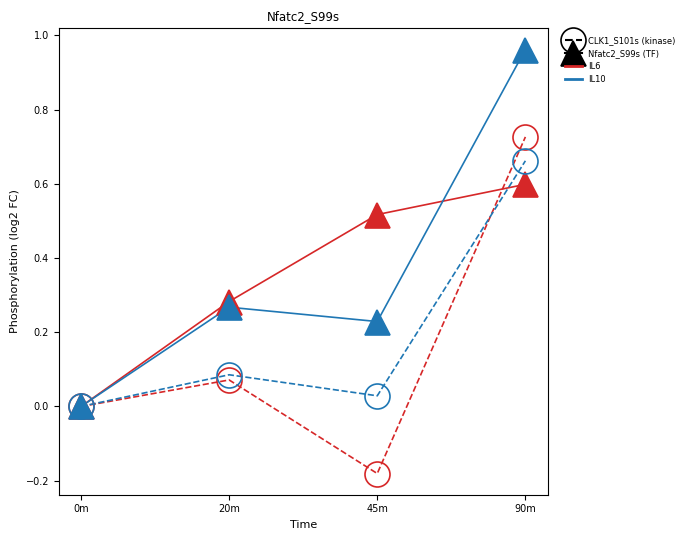

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Nfatc2_S99s.png


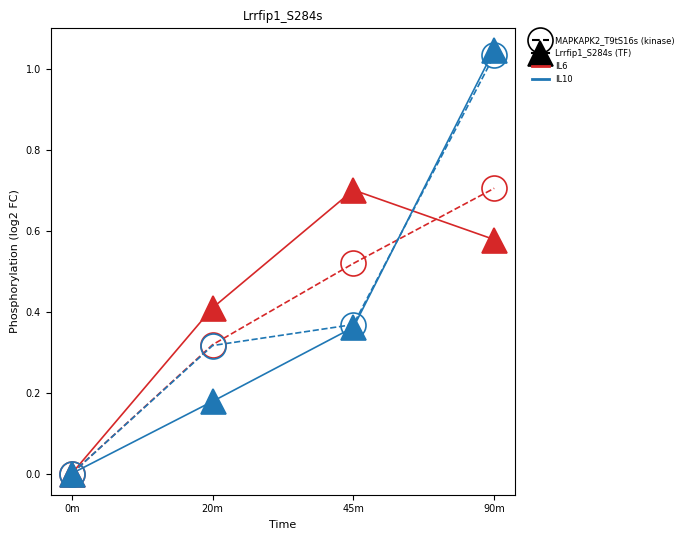

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Lrrfip1_S284s.png


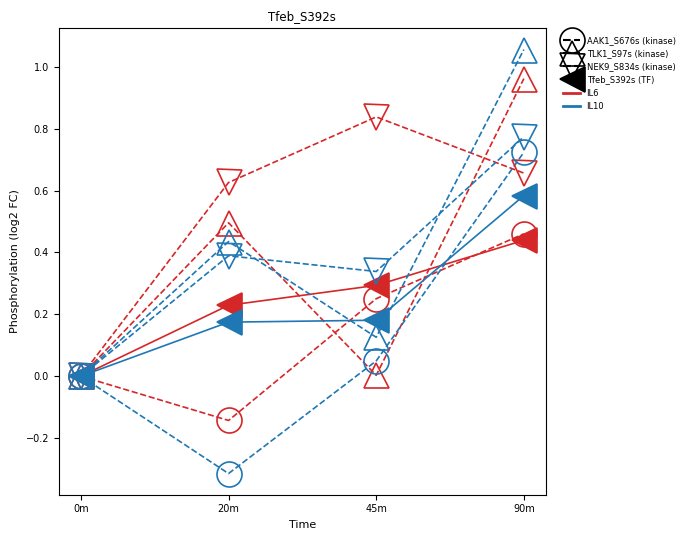

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Tfeb_S392s.png


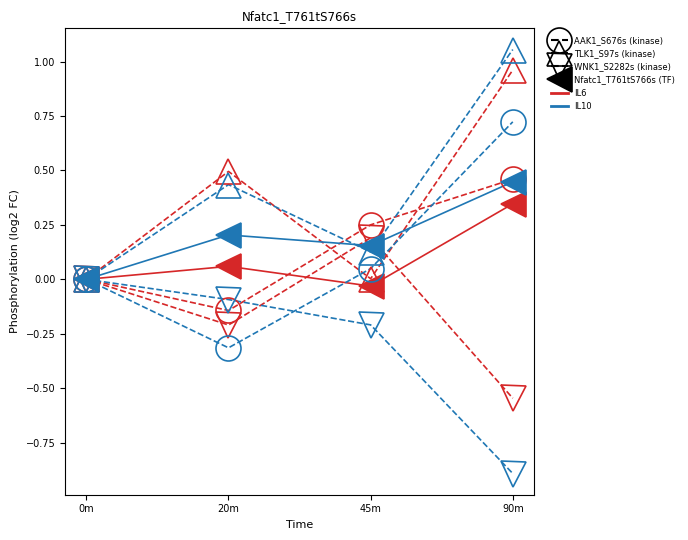

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Nfatc1_T761tS766s.png


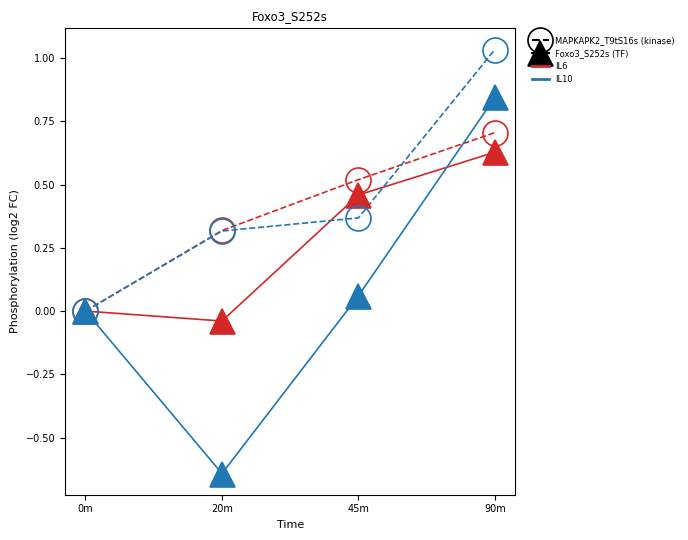

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Foxo3_S252s.png


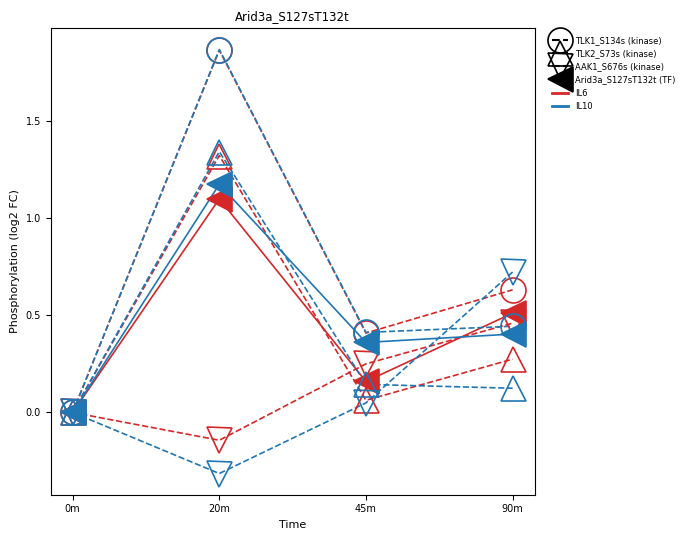

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Arid3a_S127sT132t.png


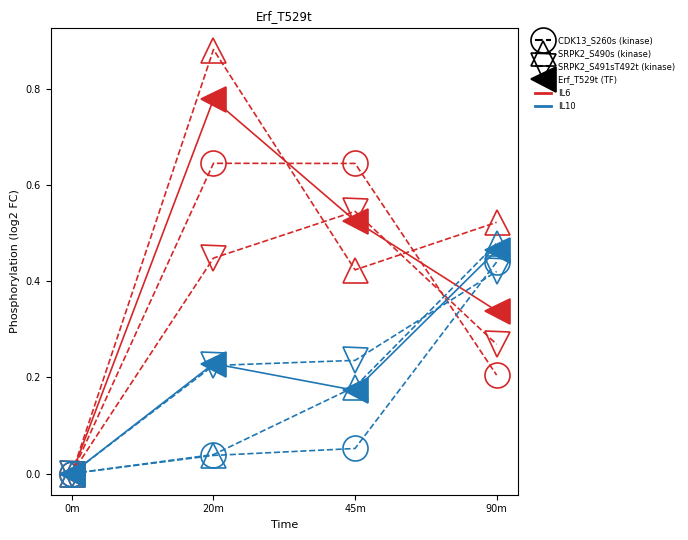

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Erf_T529t.png


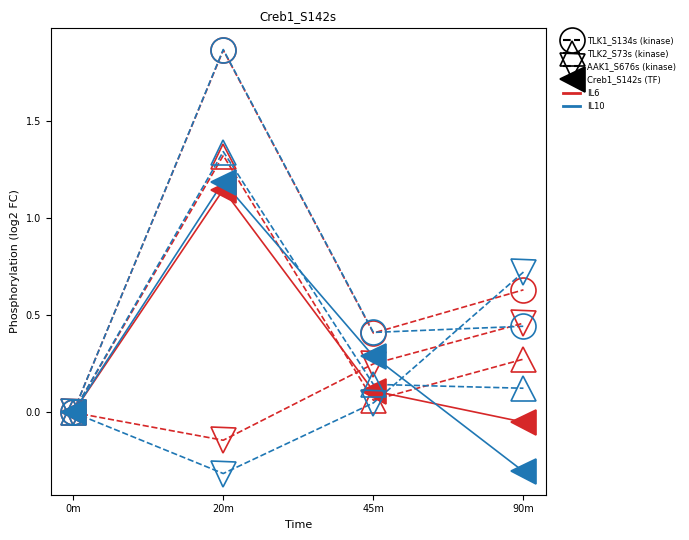

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Creb1_S142s.png


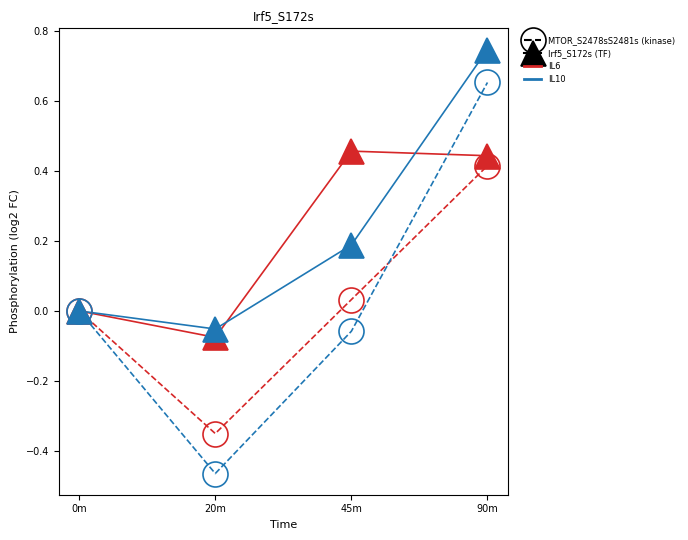

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3d_perTFsite/figures/fig3d_perTFsite_Irf5_S172s.png

Done -- 9 individual TF-site plots saved.


In [9]:
for grp in discovered_groups:
    tf_label = grp["tf_site"]
    kinases = grp["kinases"]
    safe_name = tf_label.replace("/", "_")

    fig, ax = plt.subplots(figsize=(7, 5.5))
    plot_group_on_ax(ax, kinases, [tf_label], {}, title=tf_label)
    plt.tight_layout()

    png_out = f"{out_dir}/figures/fig3d_perTFsite_{safe_name}.png"
    svg_out = f"{out_dir}/figures/fig3d_perTFsite_{safe_name}.svg"
    plt.savefig(png_out, dpi=300, bbox_inches="tight")
    plt.savefig(svg_out, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {png_out}")

print(f"\nDone -- {len(discovered_groups)} individual TF-site plots saved.")